# CMPS 360 | Data Science Fundamentals
## A/B Testing: Website Button Redesign — Worked Example

**Question:** Does a redesigned button increase completed registrations? Visitors are randomly assigned to the original **Sign Up** button (A) or the new **Get Started Free** button (B). Both versions say **Join our platform**.

This notebook follows the six steps below and uses a pre-specified **one-sided two-proportion z-test** at $\alpha=0.05$. The results are **illustrative, not actual experiment results**. For the practical-significance discussion, assume the team pre-specifies a minimum worthwhile improvement of **2 percentage points**; the actual threshold should reflect costs and benefits.

In [1]:
# Core imports and illustrative experiment data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

ALPHA = 0.05
PRACTICAL_THRESHOLD = 0.02  # Illustrative decision threshold, not a measured value
results = pd.DataFrame({
    "Version": ["A (Control)", "B (Treatment)"],
    "Visitors": [1000, 1000],
    "Registrations": [100, 130]
})
results["Did not register"] = results["Visitors"] - results["Registrations"]
results["Conversion rate"] = results["Registrations"] / results["Visitors"]
results

,Version,Visitors,Registrations,Did not register,Conversion rate
0,A (Control),1000,100,900,0.10
1,B (Treatment),1000,130,870,0.13


## Step 1. Define the experiment and decision problem

- **Experimental units:** Unique eligible visitors, randomly assigned once and kept in the same group.
- **Control A:** The original **Sign Up** button under **Join our platform**.
- **Treatment B:** The redesigned **Get Started Free** button under the same heading.
- **Response variable:** Whether each assigned visitor completes registration during a pre-specified observation window.
- **Primary metric:** Conversion rate = completed registrations / assigned visitors.
- **Decision:** Deploy B, retain A, or run another experiment.

### Why random assignment matters
Randomly assign visitors to A or B, for example with a 50/50 split. Assignment balances visitor characteristics on average, making a difference in registration more credibly attributable to the button redesign. Keep assignment stable across visits and include all assigned eligible visitors in the analysis.

### Threats to validity
1. **Unequal exposure or technical performance:** Loading problems, device incompatibility, or an unexpected allocation imbalance can affect the groups differently.
2. **Outcome or attrition bias:** Missing registration events or excluding visitors after assignment can bias the estimated effect.

Other concerns include visitors seeing both variants, novelty effects, and limited generalizability. The design compares the complete buttons, so it cannot isolate the effect of text from other changes such as color.

## Step 2. Formulate the hypotheses

Let $p_A$ and $p_B$ denote the true registration conversion rates for buttons A and B.

$$H_0: p_B-p_A \leq 0$$
$$H_1: p_B-p_A > 0$$

A **one-sided test** matches the pre-specified question of whether B increases registration. Choose the direction before examining results; a one-sided test for improvement does not test for harm.

- **Significance level:** $\alpha=0.05$.
- **Type I error:** Concluding that B increases registration when it does not.

### Sample-size planning
Before collecting data, suppose the team expects a 10% baseline and wants 80% power to detect an increase to 13% with a one-sided 5% test and equal allocation. The following normal approximation estimates the number of visitors needed **per group**. The baseline, target effect, power, and stopping rule must be chosen in advance; this is a planning illustration, not post-hoc power calculated from the observed result.

In [2]:
# Approximate equal-group sample size for a one-sided two-proportion test
baseline_rate = 0.10
target_rate = 0.13
power = 0.80
planning_pooled = (baseline_rate + target_rate) / 2
z_alpha = norm.ppf(1 - ALPHA)
z_power = norm.ppf(power)
n_per_group = int(np.ceil((
    (z_alpha * np.sqrt(2 * planning_pooled * (1 - planning_pooled))
     + z_power * np.sqrt(baseline_rate * (1 - baseline_rate)
                         + target_rate * (1 - target_rate)))
    / (target_rate - baseline_rate)
)**2))
print(f"Approximate planned sample size: {n_per_group:,} visitors per group "
      f"({2*n_per_group:,} total)")
print("The illustrative dataset has 1,000 per group; it is not the planned sample.")


Approximate planned sample size: 1,398 visitors per group (2,796 total)
The illustrative dataset has 1,000 per group; it is not the planned sample.


## Step 3. Explore and summarize the observed effect

In [3]:
p_A = results.loc[0, "Conversion rate"]
p_B = results.loc[1, "Conversion rate"]
absolute_lift = p_B - p_A
relative_lift = absolute_lift / p_A
summary = pd.DataFrame({
    "Measure": ["Version A rate", "Version B rate", "Absolute lift", "Relative lift"],
    "Result": [f"{p_A:.1%}", f"{p_B:.1%}",
               f"{absolute_lift*100:.1f} percentage points", f"{relative_lift:.1%}"]
})
summary

,Measure,Result
0,Version A rate,10.0%
1,Version B rate,13.0%
2,Absolute lift,3.0 percentage points
3,Relative lift,30.0%


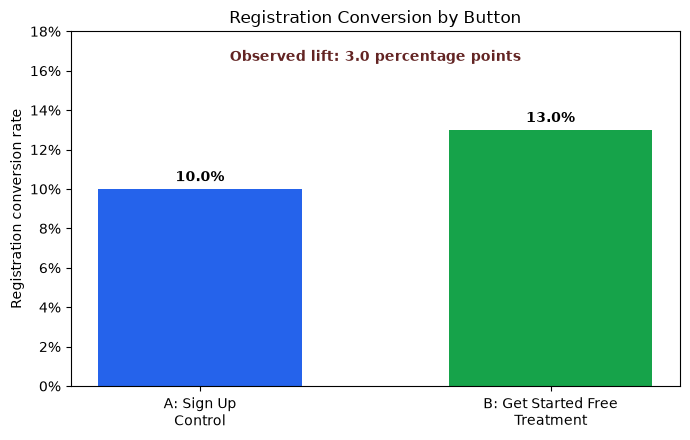

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
rates = [p_A, p_B]
bars = ax.bar(["A: Sign Up\nControl", "B: Get Started Free\nTreatment"], rates,
              color=["#2563EB", "#16A34A"], width=0.58)
ax.set_ylabel("Registration conversion rate")
ax.set_title("Registration Conversion by Button")
ax.set_ylim(0, 0.18)
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
for bar, rate in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width()/2, rate + 0.004, f"{rate:.1%}",
            ha="center", fontweight="bold")
ax.text(0.5, 0.165, f"Observed lift: {absolute_lift*100:.1f} percentage points",
        ha="center", color="#632423", fontweight="bold")
plt.tight_layout()
plt.show()

### Interpretation
In these illustrative results, A has **100 registrations out of 1,000 visitors (10%)** and B has **130 out of 1,000 (13%)**. The observed absolute improvement is **3 percentage points**, or a **30% relative increase** over A. Sampling uncertainty must still be evaluated.

## Step 4. Conduct the hypothesis test

In [5]:
# One-sided two-proportion z-test, calculated transparently
x_A, n_A = results.loc[0, ["Registrations", "Visitors"]]
x_B, n_B = results.loc[1, ["Registrations", "Visitors"]]
pooled_p = (x_A + x_B) / (n_A + n_B)
se_pooled = np.sqrt(pooled_p * (1 - pooled_p) * (1/n_A + 1/n_B))
z_stat = (p_B - p_A) / se_pooled
p_value = norm.sf(z_stat)
print(f"Pooled proportion: {pooled_p:.3f}")
print(f"Pooled standard error: {se_pooled:.6f}")
print(f"z statistic: {z_stat:.4f}")
print(f"One-sided p-value: {p_value:.4f}")
print("Decision: Reject H0" if p_value < ALPHA else "Decision: Fail to reject H0")

Pooled proportion: 0.115
Pooled standard error: 0.014267
z statistic: 2.1027
One-sided p-value: 0.0177
Decision: Reject H0


### Assumptions and conclusion
- Assume visitors were randomly assigned and observations are independent, with one outcome per visitor.
- The large-count condition holds: A has 100 registrations and 900 non-registrations; B has 130 and 870.
- The calculation assumes the test and stopping point were fixed in advance, with no unadjusted repeated looks or multiple primary comparisons.

Because $p\approx0.0177<0.05$, reject $H_0$ in this illustration. The data provide statistically significant evidence that B increases registration, under these assumptions. Statistical significance does not by itself establish practical importance.

## Step 5. Estimate uncertainty and assess practical significance

In [6]:
# Unpooled two-sided 95% confidence interval for p_B - p_A
se_unpooled = np.sqrt(p_B*(1-p_B)/n_B + p_A*(1-p_A)/n_A)
z_crit = norm.ppf(1 - ALPHA/2)
ci_low = absolute_lift - z_crit*se_unpooled
ci_high = absolute_lift + z_crit*se_unpooled
print(f"Observed difference: {absolute_lift*100:.1f} percentage points")
print(f"95% CI: [{ci_low*100:.1f}, {ci_high*100:.1f}] percentage points")
print(f"Illustrative practical threshold: {PRACTICAL_THRESHOLD*100:.1f} percentage points")

Observed difference: 3.0 percentage points
95% CI: [0.2, 5.8] percentage points
Illustrative practical threshold: 2.0 percentage points


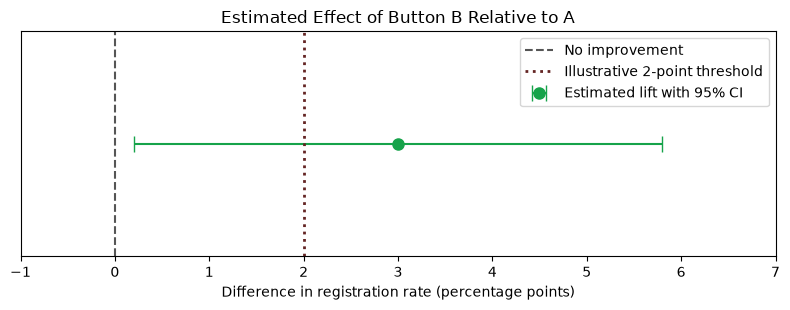

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.errorbar(absolute_lift*100, 0,
    xerr=[[100*(absolute_lift-ci_low)], [100*(ci_high-absolute_lift)]],
    fmt="o", color="#16A34A", capsize=6, markersize=8,
    label="Estimated lift with 95% CI")
ax.axvline(0, color="#555555", linestyle="--", label="No improvement")
ax.axvline(PRACTICAL_THRESHOLD*100, color="#632423", linestyle=":", linewidth=2,
           label="Illustrative 2-point threshold")
ax.set_yticks([])
ax.set_xlim(-1, 7)
ax.set_xlabel("Difference in registration rate (percentage points)")
ax.set_title("Estimated Effect of Button B Relative to A")
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation
The observed improvement is **3.0 percentage points**, with an approximate two-sided **95% confidence interval of 0.2 to 5.8 percentage points**. This range describes effects consistent with the data under the model and its assumptions. It excludes zero, but includes effects smaller than the illustrative 2-point practical threshold. The point estimate exceeds that threshold; the interval does not establish that the true improvement does. A two-sided 95% interval and a one-sided 5% test do not always lead to the same decision, although both indicate a positive effect here.

## Step 6. Make a recommendation and evaluate limitations

In [8]:
recommendation = pd.DataFrame({
    "Decision factor": ["Observed lift", "Significance", "95% CI",
                        "Practical threshold", "Guardrails", "Action"],
    "Finding": [f"{absolute_lift*100:.1f} percentage points ({relative_lift:.0%} relative)",
                f"One-sided p={p_value:.4f}",
                f"[{ci_low*100:.1f}, {ci_high*100:.1f}] percentage points",
                "Point estimate exceeds 2 points; lower CI bound does not",
                "Bounce rate and page performance not provided",
                "Run a pre-planned follow-up experiment"]
})
recommendation

,Decision factor,Finding
0,Observed lift,3.0 percentage points (30% relative)
1,Significance,One-sided p=0.0177
2,95% CI,"[0.2, 5.8] percentage points"
3,Practical threshold,Point estimate exceeds 2 points; lower CI boun...
4,Guardrails,Bounce rate and page performance not provided
5,Action,Run a pre-planned follow-up experiment


### Recommendation
**Run another pre-planned experiment rather than immediately deploying B.** The illustrative data show a statistically significant 3-point observed lift, but the interval includes improvements smaller than the assumed 2-point threshold. Bounce rate and page performance have not been measured here, so we cannot conclude that the guardrails are acceptable. Retaining A is also reasonable until the evidence and guardrails support a deployment decision.

### Limitations
1. These are illustrative aggregate counts, not actual visitor-level experiment results.
2. Random assignment, independent visitors, consistent exposure, and accurate registration tracking are assumed, not verified by these counts.
3. The conversion rate does not measure bounce rate, page performance, registration quality, or longer-term outcomes.
4. Results may differ across devices, visitor populations, or time periods.
5. Comparing complete designs does not identify which button feature caused a difference.

### Peeking and multiple testing
Repeatedly checking a fixed-horizon test and stopping when it becomes significant can inflate the false-positive rate. Pre-specify the sample size and analysis time, or use a properly designed sequential test. Testing multiple button designs or choosing among many metrics can also inflate false positives. Pre-register one primary metric and comparison; adjust a family of comparisons when appropriate.

For illustration, the next cell shows the probability of at least one false positive across 20 **independent** button comparisons if every null hypothesis is true. Comparisons sharing a control are generally dependent, so the exact formula need not apply to them.

### Follow-up and guardrails
Run a new, adequately powered experiment with a pre-specified stopping rule and completed registrations as the primary metric. Define acceptable bounce-rate and page-performance limits in advance, measure both for A and B, and investigate tracking and accessibility. Deploy B only if the evidence supports a sufficiently valuable improvement and guardrails remain acceptable.

In [9]:
familywise_false_positive_risk = 1 - (1 - ALPHA)**20
print(f"Chance of at least one false positive across 20 independent button comparisons: "
      f"{familywise_false_positive_risk:.1%}")

Chance of at least one false positive across 20 independent button comparisons: 64.2%

## Executive recommendation
In this illustrative experiment, the original **Sign Up** button converted **100/1,000 visitors (10%)**, while **Get Started Free** converted **130/1,000 (13%)**: an observed lift of **3 percentage points** or **30% relative**. The pre-specified one-sided two-proportion z-test gives **p ≈ 0.0177**, and the approximate two-sided 95% confidence interval is **0.2 to 5.8 percentage points**. The interval includes effects below the assumed 2-point practical threshold, and bounce-rate and page-performance guardrails are unavailable. **Run a pre-planned follow-up experiment before full deployment**, and retain A until the evidence and guardrails justify a change.